# Семинар 4: Методы оптимизации, Accelerate и HF Trainer

На предыдущем курсе мы обсуждали градиентный спуск и некоторые его модификации. Для обучения нейронных сетей обычно используют более продвинутые методы оптимизации, которые основаны на известном нам градиентном спуске. Сегодня мы посмотрим на то, как использовать их в **PyTorch**, а также разберём две библиотеки из экосистемы Hugging Face, которые сокращают количество рутинного кода в обучении: **Accelerate** и **Trainer** из `transformers`.

### План семинара
1. Оптимизируем функцию одной переменной в **PyTorch**
2. Изучаем разные методы оптимизации
3. Работаем с **PyTorch Optimizer**
4. Работаем с **PyTorch Scheduler**
5. Ручной цикл обучения → **Accelerate** → **HF Trainer**
6. Сравниваем работу разных оптимизаторов

In [ ]:
try:
    import accelerate, transformers, torchmetrics, torchvision  # noqa
except Exception:
    !pip -q install accelerate transformers torchmetrics torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.6 MB/s eta 0:00:00


In [ ]:
import os
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm import tqdm

In [ ]:
from accelerate.utils import set_seed

set_seed(42)  # фиксирует random, numpy и torch (в т.ч. на всех GPU)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

## Оптимизируем функцию одной переменной в **PyTorch**
Как вам показали на лекции, большинство методов машинного обучения сводятся к простому поиску параметров, который бы минимизировал ошибку на тренировочной выборке:
$$
\min_{\theta}L(p_{\theta}(X), Y)
$$
Здесь:
* $L$ - некоторый лосс,
* $p_{\theta}$ - нейронная сеть с параметрами $\theta$
* $X$ - данные для обучения,
* $Y$ - ответы

Давайте руками напишем алгоритм для поиска минимума функции $f(x) = x^{3} - 2x^{2} + 2$.

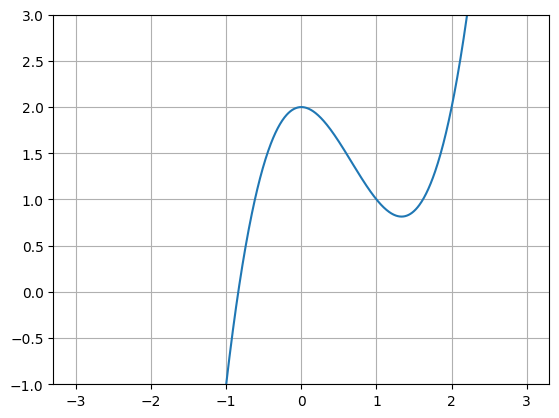

In [ ]:
func = lambda x: x**3 - 2 * x**2 + 2
d_func = lambda x: 3 * x**2 - 4 * x # x(3x-4)
x = np.linspace(-3, 3, 1000)
plt.ylim([-1, 3])
plt.plot(x, func(x))
plt.grid()
plt.show()

Определим функцию для оптимизации $f(x)$, которая должна принимать на вход learning rate и максимальное количество итераций.

In [ ]:
def find_minimum_first_order(
    learning_rate=0.01, eps=1e-4, max_iterations=1000, anneal_learning_rate=None
):
    i = 0
    x_old, x_new = 0, 2
    x_list, y_list = [x_old], [func(x_old)]

    if not anneal_learning_rate:
        anneal_learning_rate = lambda lr, step: lr

    while abs(x_new - x_old) > eps and i < max_iterations:
        learning_rate = anneal_learning_rate(learning_rate, step=i)
        x_old = x_new

        x_new = x_old - learning_rate * d_func(x_old)

        x_list.append(x_new)
        y_list.append(func(x_new))
        i += 1

    print("Найденный локальный минимум:", x_new)
    print("Количество шагов:", len(x_list))

    plt.figure(figsize=[6, 4])
    plt.ylim([-3, 8])
    plt.scatter(x_list, y_list, c="r", edgecolors="k")
    plt.plot(x_list, y_list, c="r")
    plt.plot(x, func(x), c="b")
    plt.title("Descent trajectory")
    plt.grid()
    plt.show()

Попробуем различные `learning_rate` и посмотрим на поведение оптимизации.

Найденный локальный минимум: 1.3577577123861129
Количество шагов: 729


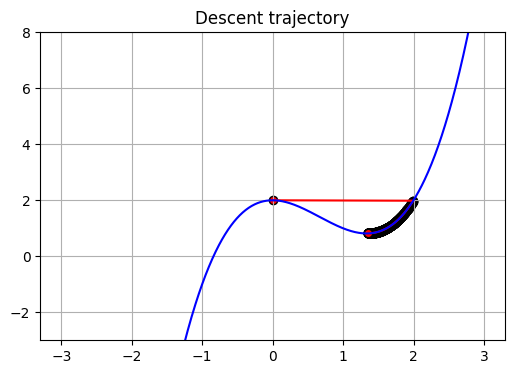

In [ ]:
find_minimum_first_order(0.001)

Слишком мало, будем очень долго идти к локальному минимуму.

Найденный локальный минимум: 1.3356881625009205
Количество шагов: 129


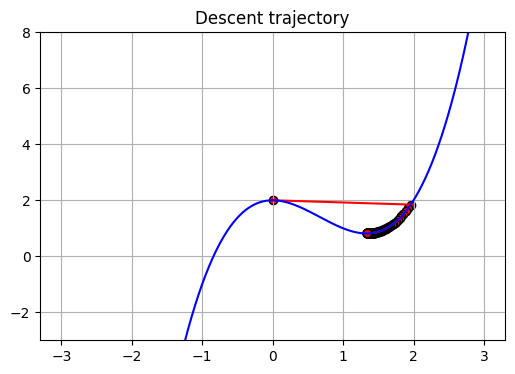

In [ ]:
find_minimum_first_order(0.01)

Уже лучше.

Найденный локальный минимум: 1.3333495713163788
Количество шагов: 8


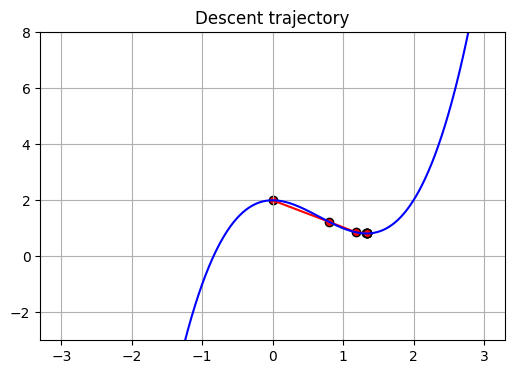

In [ ]:
find_minimum_first_order(0.3)

In [ ]:
find_minimum_first_order(0.6)

OverflowError: (34, 'Numerical result out of range')

Ууупс, получили Overflow. Значит learning rate слишком большой.

Хорошая стратегия — начинать с достаточно большого шага (повышаем вероятность не застрять в одном оптимуме, а поисследовать ландшафт функции потерь), но постепенно его уменьшать, чтобы в итоге сойтись в какой-то локальный минимум.

In [ ]:
find_minimum_first_order(0.6, anneal_learning_rate=lambda lr, step: 0.3 * lr) # 0.6 -> 0.18 -> ...

## Изучаем разные методы оптимизации

### Stochastic GD и Mini-batch GD
SGD - это же самый gradient descent, но подсчет градиентов производится не по всему множеству данных, а по отдельно взятому сэмплу. Очевидно, такая оценка градиента будет очень шумной, что потребует большего числа итераций. Поэтому обычно используют Mini-batch GD, где мы оцениваем градиент по $m$ сэмплам, а не по одному. У такого подхода ниже дисперсия в сравнении с обычным SGD, что приводит к более стабильному процессу оптимизации. Одно из основных преимуществ данного подхода - нет необходимости работать со всей выборкой для вычисления градиентов, что позволяет не только значительно сокращать время одной итерации, но и уменьшить потребление памяти (что критично, когда мы работаем с тяжелыми объектами и большими выборками, а вычислительные ресурсы у нас ограничены).

$$
w^t = w^{t-1} - \eta_t \frac{1}{m} \sum_{j = 1}^{m}\nabla L(y_{t,j}, a(x_{t, j})
$$

### Momentum
Попытаемся добавить эффект инерции. Теперь, вместо того чтобы двигаться строго в направлении градиента, которое мы получили на последней итерации, мы стараемся продолжить движение в том же направлении, в котором двигались ранее. То есть у нашей точки, которая спускается по многомерной поверхности, появляется импульс (momentum), который контролируется при помощи параметра $\alpha$. Он определяет какую часть прошлого градиента мы хотим использовать на текущем шаге.
$$
h_t = \alpha h_{t-1} + \eta_{t}\nabla Q(w^{t-1}), \\
w^t =w^{t-1} - h_t
$$


![Momentum](https://github.com/hse-ds/iad-deep-learning/blob/master/2022/seminars/sem04/static/sgd_momentum.png?raw=1)

### Nesterov Momentum
Можно несколько модифицировать формулу, используя оценку того, куда мы попадем на следующей итерации:

$$
h_t = \alpha h_{t-1} + \eta_{t}\nabla Q(w^{t-1} - \alpha h_{t-1}), \\
w^t =w^{t-1} - h_t
$$


### Адаптивные варианты градиентного спуска
Во всех предыдущих алгоритмах у нас был фиксированный learning rate. Рассмотрим адаптивные модификации, которые подстраивают темп обучения так, чтобы делать большие или маленькие обновления отдельных параметров. Например, может сложиться ситуация, когда некоторые веса близки к своим локальным минимумам (тогда их разумнее менять медленнее), а другие - далеки от своих локальных минимумов (а значит, их можно изменять  быстрее). Подобные методы часто сходятся быстрее.

#### Adagrad

Идея: давайте накапливать историю изменений по каждому параметру и учитывать эту историю на очередной итерации.

$$
G_j^t = G_j^{t-1} + (\nabla Q(w^{t-1}))_j^2, \\
w_j^t = w_j^{t-1} - \frac{\eta_t}{\sqrt(G_j^t + eps)} (\nabla Q(w^{t-1}))_j
$$

В матрице $G$ мы накапливаем обшее значение градиента по всей истории обучения.

Как видно из формулы, что скорость обучения все время уменьшается, но по-разному для разных $w_j$.

Однако у этого подхода есть проблема: $G$ все время увеличивается, поэтому скорость обучения иногда уменьшается слишком быстро.

#### RMSprop
RMSprop исправляет эту проблему при помощи сглаживания:

$$
G_j^t = \alpha G_j^{t-1} + (1 - \alpha) (\nabla Q(w^{t-1}))_j^2, \\
w_j^t = w_j^{t-1} - \frac{\eta_t}{\sqrt(G_j^t + eps)} (\nabla Q(w^{t-1}))_j
$$

Параметр $\alpha$ определяет, насколько быстро мы "забываем" градиенты, которые считали на предыдущих итерациях.

#### Adam
Совместим идеи Momentum и RMSprop:

$$
m_t^j = \frac{\beta_1 m_j^{t-1} + (1 - \beta_1)(\nabla Q(w^{t-1}))_j}{1 - \beta_1^t} \\
v_t^j = \frac{\beta_2 v_j^{t-1} + (1 - \beta_2)(\nabla Q(w^{t-1}))_j}{1 - \beta_2^t} \\
w_j^t = w_j^{t-1} - \frac{\eta_t}{\sqrt(v_j^t) + eps}m_j^t
$$

Основным достоинством Adam является то, что он практически не требует настройки, поэтому на практике используется очень часто.

#### Nadam

Можно совместить Adam и Nesterov Momentum... Формулы можно посмотреть, например, в [документации](https://docs.pytorch.org/docs/stable/generated/torch.optim.NAdam.html)

#### Дальнейшие модификации: AdamW и т.д.

Начиная с ~2017 года появилось несколько громких работ, которые показывают, что в случае наличия нескольких оптимумов (почти всегда на практике) адаптивные методы могут приходить к необобщающимся локальным решениям и обычный SGD часто  показывает результат лучше. Теоретические работы подтверждались наблюдениями при обучении сеток на практике - действительно иногда SGD выигрывает у Adam. Это стало толчком к созданию многочисленных модификаций Adam. Вдаваться в детали этих модификаций мы не будем, но упомянем одну из них, пожалуй, наиболее популярную на текущий момент, AdamW ([документация](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html)).

####  Что это означает на практике:
- если вы располагаете достаточным объемом вычислительных ресурсов (и времени) правильно проводить эксперименты с разными модификациями GD (при этом, даже SGD не нужно сбрасывать со счетов) - это вызвано сложными ланшафтами функций потерь, возникающих при обучении глубоких сетей (разные алгоритмы или один и тот же алгоритм, но с разными параметрами, могут сойтись к разным локальным оптимумам);
- по умолчанию, можно использовать Adam или его модификации AdamW, если не хочется мучиться с настройкой параметров оптимизатора

### Работаем с PyTorch Optimizer

Очевидно, что для обучения нейронных сетей не нужно каждый раз писать алгоритм оптимизации весов, самые популярные методы уже реализованы, например, в torch.optim. Описание методов можно найти в [документации](https://pytorch.org/docs/stable/optim.html#algorithms).

In [ ]:
[elem for elem in dir(torch.optim) if not elem.startswith("_")]

Основные методы PyTorch Optimizer:
* __step__ - обновить веса
* __zero_grad__ - занулить градиенты (напоминаем, что **по умолчанию градиенты в PyTorch аккумулируются**) ~ `for each param in params: param.grad = None`
* __state_dict__ - получить текущее состояние Optimizer. Например, для адаптивных методов в состоянии хранятся аккумулированные градиенты


### Как создать инстанс PyTorch Optimizer?

Для того чтобы создать инстанс оптимизатора, достаточно передать ему параметры модели (их можно получить при помощи функции `parameters()`) и гиперпараметры для метода оптимизации.

Пример:

In [ ]:
?torch.optim.SGD

In [ ]:
model = torch.nn.Linear(1, 1)
list(model.named_parameters()), torch.optim.SGD(model.parameters(), lr=0.01)

Альтернативный способ (полезно, например, для transfer learning, когда мы хотим, чтобы предобученная модель тренировалась с другим learning rate):

In [ ]:
model = torch.nn.ModuleDict(
    {"linear_1": torch.nn.Linear(1, 1), "linear_2": torch.nn.Linear(2, 2)}
)
torch.optim.SGD(
    [
        {"params": model["linear_1"].parameters(), "lr": 0.3},
        {"params": model["linear_2"].parameters()},
    ],
    lr=0.5,
)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.3
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0

Parameter Group 1
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.5
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

### Работаем с PyTorch Scheduler

В начале семинара мы уменьшили количество шагов до сходимости следующим образом: начали с достаточно большого шага, а потом постепенно его уменьшили, чтобы стабилизировать процесс обучения в минимуме. Оказывается есть много способов менять оптимизацию таким образом. Они называются Schedulers.

In [ ]:
[elem for elem in dir(torch.optim.lr_scheduler) if not elem.startswith("_")]

['Any',
 'ChainedScheduler',
 'ConstantLR',
 'CosineAnnealingLR',
 'CosineAnnealingWarmRestarts',
 'Counter',
 'CyclicLR',
 'EPOCH_DEPRECATION_WARNING',
 'ExponentialLR',
 'LRScheduler',
 'LambdaLR',
 'LinearLR',
 'Literal',
 'MultiStepLR',
 'MultiplicativeLR',
 'OneCycleLR',
 'Optimizer',
 'PolynomialLR',
 'ReduceLROnPlateau',
 'Self',
 'SequentialLR',
 'StepLR',
 'SupportsFloat',
 'TYPE_CHECKING',
 'Tensor',
 'TypedDict',
 'annotations',
 'bisect_right',
 'cast',
 'inf',
 'math',
 'override',
 'partial',
 'ref',
 'types',
 'warnings',
 'wraps']

Основные методы PyTorch Scheduler:
* __step__ - обновление размера шага. *Обычно вызывается **1 раз за эпоху**, а не каждый шаг оптимизатора.*
* __state_dict__ - получить текущее состояние Scheduler: текущий LR, количество пройденных шагов и дополнительные параметры.


### Как создать инстанс PyTorch Scheduler?

Достаточно передать `optimizer` и гиперпараметры для метода.

Пример:

In [ ]:
model = torch.nn.Linear(1, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
scheduler_func = lambda epoch: 0.65**epoch
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, scheduler_func)

Сделаем пару небольших функций для отрисовки изменения шага обучения на разных шедулерах:

In [ ]:
def get_simple_model_optimizer():
    simple_model = torch.nn.Linear(2, 1)
    simple_optimizer = torch.optim.SGD(model.parameters(), lr=100)
    return simple_model, simple_optimizer


def draw_learning_rate_curve(optimizer, scheduler):
    lrs = []
    for i in range(100):
        optimizer.step()
        lrs.append(optimizer.param_groups[0]["lr"])
        scheduler.step()
    plt.grid()
    plt.plot(range(100), lrs)

### Примеры различных шедулеров в **PyTorch**

#### [Lambda LR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html#torch.optim.lr_scheduler.LambdaLR)

При каждом обновлении learning rate меняется согласно заданного (например, в виде функции) закону

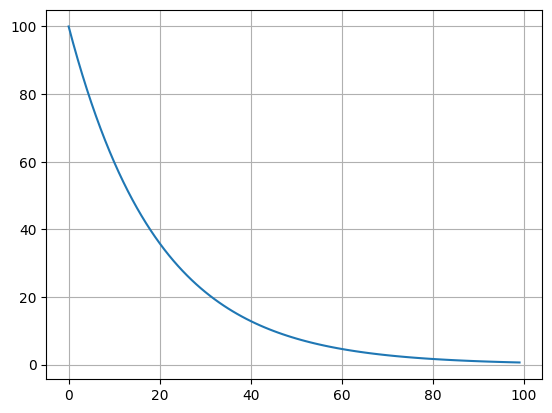

In [ ]:
model, optimizer = get_simple_model_optimizer()
lambda_func = lambda epoch: 0.95**epoch
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda_func)
draw_learning_rate_curve(optimizer, scheduler)

#### [StepLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html#torch.optim.lr_scheduler.StepLR)
Каждые `step_size` эпох уменьшает LR в `gamma` раз.

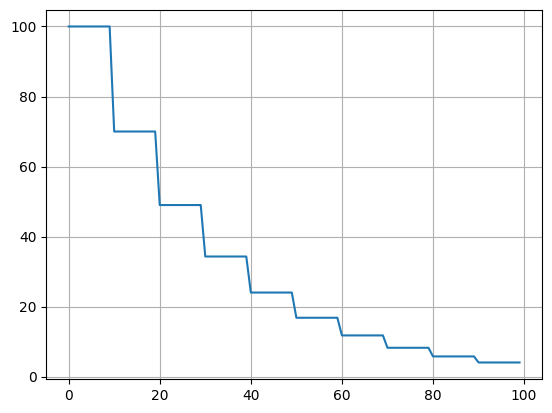

In [ ]:
model, optimizer = get_simple_model_optimizer()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.7)
draw_learning_rate_curve(optimizer, scheduler)

#### [CosineAnnealingLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html)

Иногда имеет смысл не только снижать learning rate, но и делать цикличным.

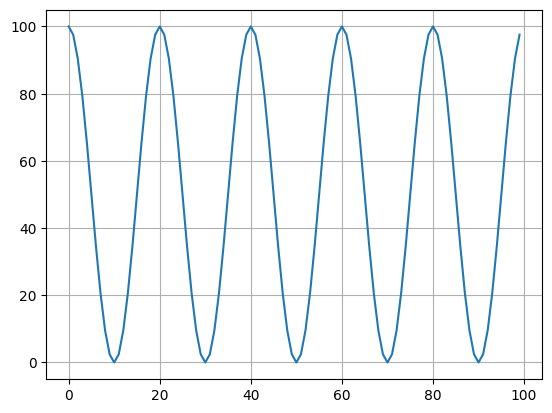

In [ ]:
model, optimizer = get_simple_model_optimizer()
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=0)
draw_learning_rate_curve(optimizer, scheduler)

## От ручного цикла к фреймворкам

Цикл обучения почти всегда выглядит одинаково: перенести батч на устройство, сделать forward, посчитать лосс, `backward`, шаг оптимизатора, обнулить градиенты, иногда шаг шедулера, посчитать метрики на валидации. Писать это каждый раз руками долго, и в этом коде легко ошибиться (забыть `zero_grad`, `model.eval()`, `torch.no_grad()`...).

Поэтому есть библиотеки, которые берут часть этой рутины на себя. Их удобно расположить на шкале «сколько кода остаётся за нами»:

| | Цикл пишем сами? | Что берёт на себя библиотека |
|---|---|---|
| **Чистый PyTorch** | да | ничего |
| [**Accelerate**](https://huggingface.co/docs/accelerate) | да | перенос на устройство, mixed precision, обучение на нескольких GPU, накопление градиентов |
| [**HF Trainer**](https://huggingface.co/docs/transformers/main_classes/trainer) | нет | весь цикл: оптимизатор, шедулер, warmup, логирование, eval, чекпоинты, колбэки |

Сравним все три подхода на одной и той же несложной нейросети на датасете FashionMNIST.

In [ ]:
from collections import defaultdict, namedtuple

import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchmetrics.functional import accuracy

### Подготовка данных (общее для обоих подходов)

Определим DataLoader для тренировочных и валидационных выборок

In [ ]:

fashion_mnist_train = torchvision.datasets.FashionMNIST(
    "./data", download=True, transform=transforms.Compose([transforms.ToTensor()])
)
train_dataloader = DataLoader(
    fashion_mnist_train, batch_size=128, shuffle=True, num_workers=4
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 213kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.95MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.9MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
fashion_mnist_val = torchvision.datasets.FashionMNIST(
    "./data",
    train=False,
    download=True,
    transform=transforms.Compose([transforms.ToTensor()]),
)
val_dataloader = DataLoader(fashion_mnist_val, batch_size=128, num_workers=4)

In [ ]:
idx_to_label = defaultdict(
    None,
    {
        0: "T-shirt/Top",
        1: "Trouser",
        2: "Pullover",
        3: "Dress",
        4: "Coat",
        5: "Sandal",
        6: "Shirt",
        7: "Sneaker",
        8: "Bag",
        9: "Ankle Boot",
    },
)

Давайте посмотрим глазами на несколько сэмплов

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Ankle Boot


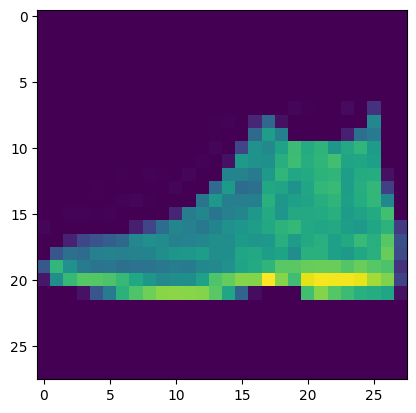

Trouser


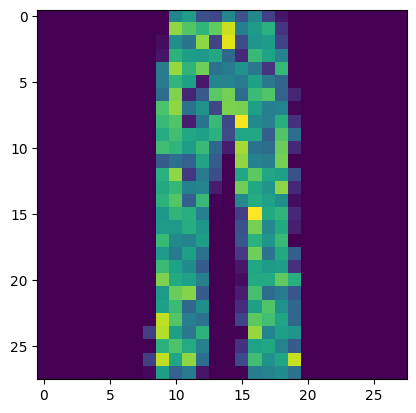

Bag


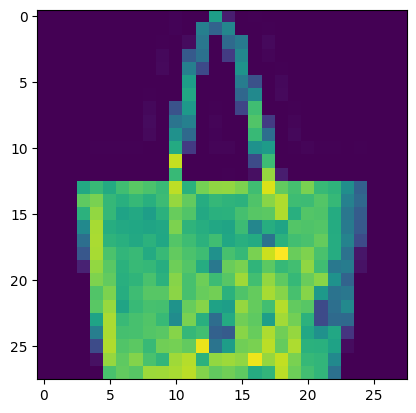

In [ ]:
for num, batch in enumerate(val_dataloader):
    images, class_nums = batch
    print(idx_to_label[int(class_nums[0])])
    plt.imshow(images[0].squeeze())
    plt.show()

    if num == 2:
      break

### Создание модели (общее для обоих подходов)



Создадим класс модели со следующей конфигурацией:

1. Conv(1->32, kernel=3, padding=1), BatchNorm, ReLU, MaxPool(2)
2. Conv(32->64, kernel=3, padding=1), BatchNorm, ReLU, MaxPool(2)
3. Flatten
4. Linear, ReLU
5. Linear

In [ ]:
class SimpleNet(torch.nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()

        self.conv1 = torch.nn.Sequential(
            torch.nn.Conv2d(1, 32, kernel_size=3, padding=1),
            torch.nn.BatchNorm2d(32),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2)
        )

        self.conv2 = torch.nn.Sequential(
            torch.nn.Conv2d(32, 64, kernel_size=3, padding=1),
            torch.nn.BatchNorm2d(64),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(), # 64 * 7 * 7
            torch.nn.Linear(64 * 7 * 7, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 10)
        )

        self.loss_func = torch.nn.CrossEntropyLoss()
        self.targets = torch.Tensor()
        self.preds = torch.Tensor()

    def _forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.classifier(x)
        return x

    def forward(self, images, target=None):
        # images ~ (batch size, num channels, height, width)
        # target ~ (batch size)
        # output ~ (batch size, num classes)
        output = self._forward(images)

        # get accuracy score and save it to self.accuracy
        if target is not None:
            loss = self.loss_func(output, target)

            self.targets = torch.cat((self.targets, target.cpu()), 0)
            pred = torch.argmax(output, dim=-1)
            self.preds = torch.cat((self.preds, pred.cpu()), 0)
            self.accuracy = accuracy(self.preds.long(), self.targets.long(), task='multiclass', num_classes=10)

        return loss if target is not None else output

    def get_accuracy(self, reset=False):
        if reset:
            self.targets = torch.Tensor()
            self.preds = torch.Tensor()
        return self.accuracy

### Гиперпараметры

In [ ]:
LossInfo = namedtuple(
    "LossInfo", ["full_train_losses", "train_epoch_losses", "eval_epoch_losses"]
)
EPOCHS = 3
LR = 0.001

### Тренировочные циклы (PyTorch)

Давайте объявим функции `train_epoch`, `validate`, `fit`.
Напомним, что структура выглядит в упрощенном виде так:
```
def train_epoch():
    for batch in train_loader:
        train_model_on_batch()
def validate():
    for batch in val_loader:
        validate_model_on_batch()
def fit():
    for epoch in range(1, num_epochs):
        train_epoch()
        validate()
```


Однако в коде выглядит довольно объемно...

In [ ]:
def train_epoch(
    model,
    data_loader,
    optimizer,
    return_losses=False,
    device="cuda:0",
):
    model = model.train()
    total_loss = 0
    num_batches = 0
    all_losses = []
    with tqdm(total=len(data_loader), file=sys.stdout) as prbar:
        for batch in data_loader:
            # move Batch to GPU
            batch = [x.to(device=device) for x in batch]
            loss = model(*batch)
            # update weights
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            # update description for tqdm
            accuracy = model.get_accuracy()
            prbar.set_description(
                f"Loss: {round(loss.item(), 4)} "
                f"Accuracy: {round(accuracy.item() * 100, 4)}"
            )
            prbar.update(1)
            total_loss += loss.item()
            num_batches += 1
            all_losses.append(loss.detach().item())
    acc = model.get_accuracy(reset=True)
    metrics = {"loss": total_loss / num_batches, "accuracy": acc}
    if return_losses:
        return metrics, all_losses
    else:
        return metrics


def validate(model, data_loader, device="cuda:0"):
    model = model.eval()
    total_loss = 0
    num_batches = 0
    with tqdm(total=len(data_loader), file=sys.stdout) as prbar:
        for batch in data_loader:
            batch = [x.to(device=device) for x in batch]
            loss = model(*batch)
            accuracy = model.get_accuracy()
            prbar.set_description(
                f"Loss: {round(loss.item(), 4)} "
                f"Accuracy: {round(accuracy.item() * 100, 4)}"
            )
            prbar.update(1)
            total_loss += loss.item()
            num_batches += 1
    acc = model.get_accuracy(reset=True)
    metrics = {"loss": total_loss / num_batches, "accuracy": acc}
    return metrics

In [ ]:
def fit(
    model,
    epochs,
    train_data_loader,
    validation_data_loader,
    optimizer,
    scheduler=None,
    device="cuda:0",
):
    all_train_losses = []
    epoch_train_losses = []
    epoch_eval_losses = []
    for epoch in range(epochs):
        # construct iterators
        train_iterator = iter(train_data_loader)
        validation_iterator = iter(validation_data_loader)
        # train step
        print(f"Train Epoch: {epoch}")
        train_metrics, one_epoch_train_losses = train_epoch(
            model=model,
            data_loader=train_iterator,
            optimizer=optimizer,
            return_losses=True,
            device=device,
        )
        # save train losses
        all_train_losses.extend(one_epoch_train_losses)
        epoch_train_losses.append(train_metrics["loss"])
        # eval step
        print(f"Validation Epoch: {epoch}")
        with torch.no_grad():
            validation_metrics = validate(
                model=model, data_loader=validation_iterator, device=device
            )
        # save eval losses
        epoch_eval_losses.append(validation_metrics["loss"])
        # scheduler step
        if scheduler:
            scheduler.step()
    return LossInfo(all_train_losses, epoch_train_losses, epoch_eval_losses)

Давайте обучим модель

In [ ]:
model = SimpleNet().to(device)
_ = fit(
    model=model,
    epochs=EPOCHS, # примерно минута на GPU в коллабе
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.SGD(model.parameters(), lr=LR),
    device=device,
)

Train Epoch: 0
Loss: 0.7181 Accuracy: 67.7817: 100%|██████████| 469/469 [00:13<00:00, 34.64it/s]
Validation Epoch: 0
Loss: 0.8033 Accuracy: 76.57: 100%|██████████| 79/79 [00:01<00:00, 60.16it/s]
Train Epoch: 1
Loss: 0.599 Accuracy: 78.2883: 100%|██████████| 469/469 [00:10<00:00, 46.52it/s]
Validation Epoch: 1
Loss: 0.5917 Accuracy: 78.95: 100%|██████████| 79/79 [00:01<00:00, 59.11it/s]
Train Epoch: 2
Loss: 0.4186 Accuracy: 80.7533: 100%|██████████| 469/469 [00:10<00:00, 46.14it/s]
Validation Epoch: 2
Loss: 0.5194 Accuracy: 80.91: 100%|██████████| 79/79 [00:01<00:00, 60.95it/s]


### Тренировочные циклы (Accelerate)

**Accelerate** — тонкая обёртка: цикл обучения остаётся нашим, библиотека убирает из него только «железную» часть. Изменения по сравнению с ручным `fit()`:

1. Создаём `Accelerator()` и пропускаем через `accelerator.prepare(...)` модель, оптимизатор и даталоадеры.
2. Убираем все `.to(device)`: подготовленные даталоадеры сами кладут батчи на нужное устройство.
3. Вместо `loss.backward()` пишем `accelerator.backward(loss)` — так корректно работают mixed precision и распределённое обучение.
4. На валидации собираем предсказания со всех процессов через `accelerator.gather_for_metrics(...)` (на одной GPU это ничего не меняет, на нескольких — без этого метрика будет посчитана только по своей части данных).

```
accelerator = Accelerator()
model, optimizer, train_loader = accelerator.prepare(model, optimizer, train_loader)

for batch in train_loader:          # батч уже на нужном устройстве
    loss = model(*batch)
    accelerator.backward(loss)      # вместо loss.backward()
    optimizer.step()
    optimizer.zero_grad()
```

In [ ]:
from accelerate import Accelerator


def fit_accelerate(
    model,
    epochs,
    train_data_loader,
    validation_data_loader,
    optimizer,
    scheduler=None,
    mixed_precision="no",  # на GPU можно поставить "fp16" или "bf16"
):
    accelerator = Accelerator(mixed_precision=mixed_precision)
    # 1. prepare: переносит модель на устройство, оборачивает даталоадеры и оптимизатор
    model, optimizer, train_data_loader, validation_data_loader = accelerator.prepare(
        model, optimizer, train_data_loader, validation_data_loader
    )

    all_train_losses = []
    for epoch in range(epochs):
        # ---- train ----
        model.train()
        progress = tqdm(
            train_data_loader,
            desc=f"Train epoch {epoch}",
            disable=not accelerator.is_local_main_process,  # один прогресс-бар на все процессы
            file=sys.stdout,
        )
        for images, target in progress:  # 2. никаких .to(device)
            loss = model(images, target)
            accelerator.backward(loss)  # 3. вместо loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            all_train_losses.append(loss.item())
            progress.set_postfix(loss=round(loss.item(), 4))
        if scheduler is not None:
            scheduler.step()  # шедулер у нас по эпохам, как в ручном fit()

        # ---- validation ----
        model.eval()
        total_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, target in validation_data_loader:
                logits = model(images)
                # 4. собираем предсказания и таргеты со всех процессов
                logits, target = accelerator.gather_for_metrics((logits, target))
                total_loss += F.cross_entropy(logits, target, reduction="sum").item()
                correct += (logits.argmax(dim=-1) == target).sum().item()
                total += target.numel()
        accelerator.print(
            f"Epoch {epoch}: val_loss={total_loss / total:.4f}, val_accuracy={correct / total:.4f}"
        )

    return all_train_losses

In [ ]:
model = SimpleNet()  # обратите внимание: без .to(device)
accelerate_losses = fit_accelerate(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.Adam(model.parameters(), lr=LR),
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train epoch 0:   0%|          | 0/469 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train epoch 0: 100%|██████████| 469/469 [00:10<00:00, 45.89it/s, loss=0.244]
Epoch 0: val_loss=0.3247, val_accuracy=0.8821
Train epoch 1: 100%|██████████| 469/469 [00:11<00:00, 39.87it/s, loss=0.128]
Epoch 1: val_loss=0.3371, val_accuracy=0.8713
Train epoch 2: 100%|██████████| 469/469 [00:13<00:00, 34.94it/s, loss=0.225]
Epoch 2: val_loss=0.2390, val_accuracy=0.9155


Тот же самый код без изменений запускается на нескольких GPU. Для этого его кладут в скрипт `train.py` и запускают через
```
accelerate config      # один раз: ответить на вопросы про железо
accelerate launch train.py
```
Именно поэтому Accelerate часто встречается в чужом коде обучения: исследовательские скрипты пишутся как обычный PyTorch, а масштабирование добавляется парой строк.

### Тренировочные циклы (HF Trainer)

**Trainer** из библиотеки `transformers` — толстый фреймворк: цикл обучения пишет он, а мы только описываем, *что* обучать. Внутри он сам использует Accelerate. Структура такая:

1) Модель, у которой `forward` принимает именованные аргументы из батча и возвращает словарь с ключами `loss` и `logits`.

2) Датасет + `data_collator`, который превращает список примеров в батч-словарь `{"pixel_values": ..., "labels": ...}`. Ключи словаря должны совпадать с аргументами `forward`.

3) `TrainingArguments` — все гиперпараметры обучения: число эпох, размер батча, learning rate, оптимизатор, шедулер, warmup, как часто логировать и валидироваться ([документация](https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments)).

4) `Trainer(model, args, train_dataset, eval_dataset, data_collator, compute_metrics)` и `trainer.train()`.

```
args = TrainingArguments(output_dir="out", num_train_epochs=10, learning_rate=1e-3, ...)
trainer = Trainer(model=model, args=args, train_dataset=..., eval_dataset=..., data_collator=...)
trainer.train()
```

Trainer создавался для трансформеров, поэтому ожидает от модели определённый «контракт». Наш `SimpleNet` возвращает просто лосс, так что напишем маленькую обёртку.

In [ ]:
class SimpleNetForTrainer(torch.nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()
        self.net = SimpleNet(dropout=dropout)

    # имена аргументов должны совпадать с ключами батча из data_collator;
    # аргумент labels Trainer узнаёт по имени и считает его таргетом
    def forward(self, pixel_values, labels=None):
        logits = self.net._forward(pixel_values)
        output = {"logits": logits}
        if labels is not None:
            output["loss"] = F.cross_entropy(logits, labels)
        return output


def collate_fn(examples):
    # torchvision отдаёт пары (картинка, класс) -> собираем батч-словарь
    images, labels = zip(*examples)
    return {"pixel_values": torch.stack(images), "labels": torch.tensor(labels)}


def compute_metrics(eval_pred):
    # Trainer сам соберёт логиты и таргеты со всей валидации (в numpy)
    logits, labels = eval_pred
    return {"accuracy": (logits.argmax(axis=-1) == labels).mean()}

Теперь все гиперпараметры обучения описываются декларативно. Обратите внимание, что оптимизатор и шедулер из первой половины семинара здесь задаются просто строками:
* `optim="adamw_torch"` — AdamW из `torch.optim` (можно `"sgd"`, `"adafactor"` и [другие](https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments.optim));
* `lr_scheduler_type="cosine"` — косинусный шедулер, но шагает он **по батчам**, а не по эпохам;
* `warmup_steps=0.1` — первые 10% шагов learning rate линейно растёт от 0 (warmup почти всегда используют при обучении трансформеров).

In [ ]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./trainer_output",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=128,
    per_device_eval_batch_size=128,
    learning_rate=LR,
    weight_decay=0.01,
    optim="adamw_torch",
    lr_scheduler_type="cosine",
    warmup_steps=0.1,  # float < 1 = доля от всех шагов обучения
    eval_strategy="epoch",  # валидация в конце каждой эпохи
    logging_steps=50,  # лосс на трейне пишется каждые 50 шагов
    save_strategy="no",  # чекпоинты нам сейчас не нужны
    report_to="none",  # сюда можно поставить "wandb" или "tensorboard"
    remove_unused_columns=False,  # у нас не HF-датасет, ничего не удаляем
    dataloader_num_workers=2,
)

trainer = Trainer(
    model=SimpleNetForTrainer(),
    args=training_args,
    train_dataset=fashion_mnist_train,
    eval_dataset=fashion_mnist_val,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.312687,0.319899,0.885000
2,0.234484,0.256915,0.906900
3,0.180525,0.229695,0.915200


TrainOutput(global_step=1407, training_loss=0.3088112025711667, metrics={'train_runtime': 29.6371, 'train_samples_per_second': 6073.469, 'train_steps_per_second': 47.474, 'total_flos': 0.0, 'train_loss': 0.3088112025711667, 'epoch': 3.0})

In [ ]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy
0.180525,0.229695,3,0.915200


{'eval_loss': 0.2296951711177826, 'eval_accuracy': 0.9152}

Вся история обучения лежит в `trainer.state.log_history` — список словарей с лоссом, learning rate и метриками. Нарисуем по нему лосс и learning rate: видно и warmup, и косинусное затухание.

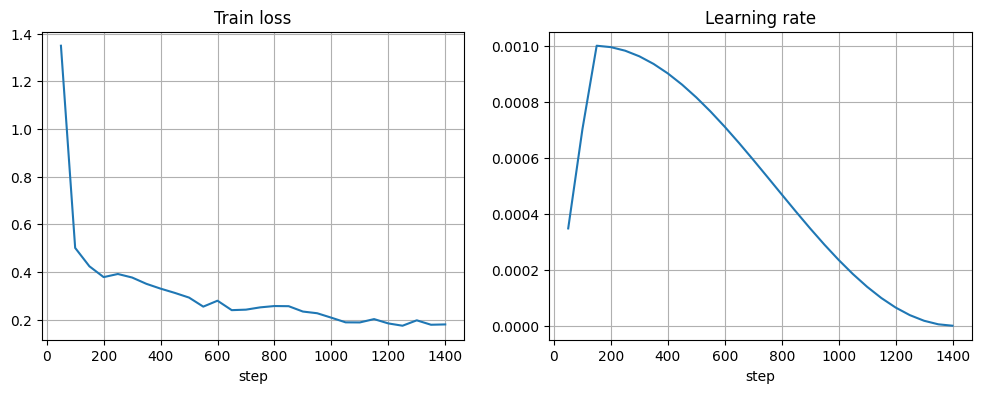

In [ ]:
train_logs = [log for log in trainer.state.log_history if "loss" in log]
steps = [log["step"] for log in train_logs]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(steps, [log["loss"] for log in train_logs])
axes[0].set_title("Train loss")
axes[0].set_xlabel("step")
axes[0].grid()
axes[1].plot(steps, [log["learning_rate"] for log in train_logs])
axes[1].set_title("Learning rate")
axes[1].set_xlabel("step")
axes[1].grid()
plt.show()

Сравним три подхода.

С **Accelerate** мы:
1. Не переносили ни модель, ни данные на GPU вручную
2. Бесплатно получили mixed precision и запуск на нескольких GPU (`accelerate launch`)
3. Сохранили полный контроль над циклом: любой нестандартный шаг (несколько моделей, GAN, RL, хитрый лосс) пишется как в обычном PyTorch

С **Trainer** мы дополнительно:
1. Не писали цикл обучения ни по эпохам, ни по батчам и не рисковали забыть `zero_grad`, `.backward()`, `model.eval()`
2. Задали оптимизатор, шедулер и warmup одной строкой каждый
3. Получили логирование (в т.ч. в wandb/tensorboard), валидацию, чекпоинты и [колбэки](https://huggingface.co/docs/transformers/main_classes/callback) (например, `EarlyStoppingCallback`)
4. Но заплатили за это «контрактом»: модель и батчи должны иметь определённый вид, а нестандартную логику приходится вписывать через переопределение методов (`compute_loss`, `training_step`) или колбэки

На практике: для стандартного обучения и дообучения моделей из `transformers` (а также поверх него работают TRL и PEFT) чаще всего берут Trainer; для всего нестандартного — свой цикл на PyTorch + Accelerate.

## Сравнение работы разных оптимизаторов

### SGD

In [ ]:
model = SimpleNet().to(device=device)
sgd_loss_info = fit(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.SGD(model.parameters(), lr=LR),
    device=device,
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train Epoch: 0
Loss: 0.8148 Accuracy: 67.7317: 100%|██████████| 469/469 [00:09<00:00, 47.58it/s]
Validation Epoch: 0
Loss: 0.7799 Accuracy: 76.52: 100%|██████████| 79/79 [00:01<00:00, 64.04it/s]
Train Epoch: 1
Loss: 0.587 Accuracy: 78.2117: 100%|██████████| 469/469 [00:09<00:00, 48.50it/s]
Validation Epoch: 1
Loss: 0.592 Accuracy: 78.38: 100%|██████████| 79/79 [00:01<00:00, 61.69it/s]
Train Epoch: 2
Loss: 0.4839 Accuracy: 80.49: 100%|██████████| 469/469 [00:14<00:00, 31.94it/s]
Validation Epoch: 2
Loss: 0.5063 Accuracy: 80.35: 100%|██████████| 79/79 [00:01<00:00, 63.12it/s]


### SGD with Momentum

In [ ]:
model = SimpleNet().to(device=device)
sgd_momentum_loss_info = fit(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.SGD(model.parameters(), momentum=0.9, lr=LR),
    device=device,
)

Train Epoch: 0
Loss: 0.3334 Accuracy: 79.53: 100%|██████████| 469/469 [00:09<00:00, 48.35it/s]
Validation Epoch: 0
Loss: 0.3104 Accuracy: 85.08: 100%|██████████| 79/79 [00:01<00:00, 62.85it/s]
Train Epoch: 1
Loss: 0.4499 Accuracy: 87.1117: 100%|██████████| 469/469 [00:09<00:00, 47.97it/s]
Validation Epoch: 1
Loss: 0.2182 Accuracy: 86.99: 100%|██████████| 79/79 [00:01<00:00, 63.16it/s]
Train Epoch: 2
Loss: 0.3053 Accuracy: 88.7783: 100%|██████████| 469/469 [00:10<00:00, 46.30it/s]
Validation Epoch: 2
Loss: 0.1825 Accuracy: 88.18: 100%|██████████| 79/79 [00:01<00:00, 46.65it/s]


### RMSprop

In [ ]:
model = SimpleNet().to(device=device)
rmsprop_loss_info = fit(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.RMSprop(model.parameters(), lr=LR),
    device=device,
)

Train Epoch: 0
Loss: 0.262 Accuracy: 82.0017: 100%|██████████| 469/469 [00:09<00:00, 46.94it/s]
Validation Epoch: 0
Loss: 0.1841 Accuracy: 87.1: 100%|██████████| 79/79 [00:01<00:00, 62.42it/s]
Train Epoch: 1
Loss: 0.2907 Accuracy: 88.8033: 100%|██████████| 469/469 [00:10<00:00, 46.13it/s]
Validation Epoch: 1
Loss: 0.214 Accuracy: 89.46: 100%|██████████| 79/79 [00:01<00:00, 58.47it/s]
Train Epoch: 2
Loss: 0.2217 Accuracy: 90.4917: 100%|██████████| 469/469 [00:09<00:00, 47.35it/s]
Validation Epoch: 2
Loss: 0.1975 Accuracy: 89.04: 100%|██████████| 79/79 [00:01<00:00, 59.18it/s]


### Adam

In [ ]:
model = SimpleNet().to(device=device)
adam_loss_info = fit(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.Adam(model.parameters(), lr=LR),
    device=device,
)

Train Epoch: 0
Loss: 0.3599 Accuracy: 86.0467: 100%|██████████| 469/469 [00:10<00:00, 45.39it/s]
Validation Epoch: 0
Loss: 0.2474 Accuracy: 88.73: 100%|██████████| 79/79 [00:01<00:00, 61.80it/s]
Train Epoch: 1
Loss: 0.2808 Accuracy: 90.6683: 100%|██████████| 469/469 [00:10<00:00, 44.87it/s]
Validation Epoch: 1
Loss: 0.1743 Accuracy: 90.31: 100%|██████████| 79/79 [00:01<00:00, 62.77it/s]
Train Epoch: 2
Loss: 0.2208 Accuracy: 91.9383: 100%|██████████| 469/469 [00:10<00:00, 44.43it/s]
Validation Epoch: 2
Loss: 0.258 Accuracy: 91.41: 100%|██████████| 79/79 [00:01<00:00, 62.11it/s]


### AdamW

In [ ]:
model = SimpleNet().to(device=device)
adamw_loss_info = fit(
    model=model,
    epochs=EPOCHS,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    optimizer=torch.optim.AdamW(model.parameters(), lr=LR),
    device=device,
)

Train Epoch: 0
Loss: 0.3939 Accuracy: 86.2633: 100%|██████████| 469/469 [00:10<00:00, 46.31it/s]
Validation Epoch: 0
Loss: 0.2354 Accuracy: 87.15: 100%|██████████| 79/79 [00:01<00:00, 57.48it/s]
Train Epoch: 1
Loss: 0.257 Accuracy: 90.5267: 100%|██████████| 469/469 [00:09<00:00, 47.92it/s]
Validation Epoch: 1
Loss: 0.1862 Accuracy: 89.88: 100%|██████████| 79/79 [00:01<00:00, 59.96it/s]
Train Epoch: 2
Loss: 0.2759 Accuracy: 91.8133: 100%|██████████| 469/469 [00:09<00:00, 47.40it/s]
Validation Epoch: 2
Loss: 0.1176 Accuracy: 90.75: 100%|██████████| 79/79 [00:01<00:00, 62.52it/s]


### Графики падения лосса при разных способах оптимизации

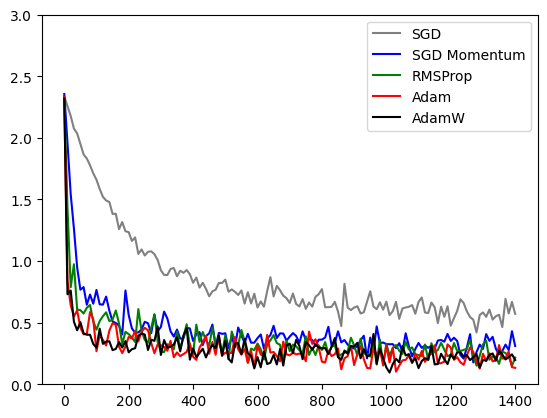

In [ ]:
plt.plot(
    np.arange(len(train_dataloader) * EPOCHS)[::10],
    sgd_loss_info.full_train_losses[::10],
    label="SGD",
    c="grey",
)
plt.plot(
    np.arange(len(train_dataloader) * EPOCHS)[::10],
    sgd_momentum_loss_info.full_train_losses[::10],
    label="SGD Momentum",
    c="blue",
)
plt.plot(
    np.arange(len(train_dataloader) * EPOCHS)[::10],
    rmsprop_loss_info.full_train_losses[::10],
    label="RMSProp",
    c="green",
)
plt.plot(
    np.arange(len(train_dataloader) * EPOCHS)[::10],
    adam_loss_info.full_train_losses[::10],
    label="Adam",
    c="red",
)
plt.plot(
    np.arange(len(train_dataloader) * EPOCHS)[::10],
    adamw_loss_info.full_train_losses[::10],
    label="AdamW",
    c="black",
)

plt.ylim(0, 3)

plt.legend()
plt.show()